# **Full JEPA Training - Encoder and Predictor Trained Jointly**
---

In `notebooks/2-vae/` the world model was built in two separate steps: a β-VAE was trained to **reconstruct pixels**, then frozen, and an MLP predictor learned the dynamics of its latents. The encoder never received any signal about what is *predictable*.

This notebook trains a **full JEPA** (Joint-Embedding Predictive Architecture; LeCun, 2022): the encoder and the predictor are trained **at the same time**, with a loss computed only in latent space. The encoder is free to keep whatever information makes the next state predictable and to discard the rest; there is no decoder and no pixel loss.

The encoder uses exactly the same convolutional stack as the VAE and the predictor is the same MLP (`JEPAPredictor`, `context_len = 2`), so the comparison with the VAE world model isolates the effect of the **training objective**. Evaluation follows the same protocol (`3-full_jepa_evaluation.ipynb`).

## **Theory**

### **Joint-embedding prediction**

For a window of frames $x_{t-k+1}, \dots, x_t, x_{t+1}$ and the action $a_t$:

$$z_{t-j} = E_\theta(x_{t-j}), \qquad \hat{z}_{t+1} = P_\phi\big(z_{t-k+1:t},\ a_t\big), \qquad \bar{z}_{t+1} = E_{\bar\theta}(x_{t+1})$$

where $E_\theta$ is the **context encoder**, $P_\phi$ the predictor and $E_{\bar\theta}$ the **target encoder**. The prediction loss is

$$\mathcal{L}_{\text{pred}} = \frac{1}{B\,d}\sum_{i=1}^{B} \big\lVert \hat{z}^{(i)}_{t+1} - \mathrm{sg}\big(\bar{z}^{(i)}_{t+1}\big) \big\rVert_2^2$$

with $\mathrm{sg}(\cdot)$ the stop-gradient operator: gradients flow into the predictor and the context encoder, never into the target.

### **Representation collapse**

If $\theta$ and $\phi$ are trained only with $\mathcal{L}_{\text{pred}}$, there is a trivial solution: map **every** frame to the same constant vector, $E_\theta(x) = c$. The predictor then outputs $c$ and the loss is exactly zero, but the representation carries no information. This is *representation collapse*, the central difficulty of joint-embedding methods (with a frozen VAE it cannot happen, because the reconstruction objective fixes the latents). Two complementary mechanisms are used here.

### **1. EMA target encoder (BYOL, I-JEPA)**

The target encoder is not trained by gradient descent. Its weights are an **exponential moving average** of the context encoder's weights, updated after every optimiser step:

$$\bar\theta \leftarrow m\,\bar\theta + (1 - m)\,\theta, \qquad m \in [0, 1)$$

With the stop-gradient, the context encoder cannot move the targets towards a constant to reduce the loss; the targets change only slowly, following the encoder (Grill et al., 2020; Assran et al., 2023). This makes collapse much slower and empirically often avoids it, but it is **not a guarantee**: nothing in the loss explicitly rewards information.

### **2. VICReg variance and covariance regularisation**

VICReg (Bardes et al., 2022) adds explicit terms that forbid collapse. On a batch of $n$ embeddings $h \in \mathbb{R}^{n\times D}$:

$$\mathcal{L}_{\text{var}} = \frac{1}{D}\sum_{j=1}^{D} \max\!\big(0,\ \gamma - \sqrt{\mathrm{Var}(h_{:,j}) + \epsilon}\big), \qquad \mathcal{L}_{\text{cov}} = \frac{1}{D}\sum_{i \ne j} C(h)_{ij}^2$$

- The **variance** term is a hinge that keeps the standard deviation of every dimension above $\gamma = 1$ across the batch: a constant embedding is penalised.
- The **covariance** term pushes the off-diagonal entries of the covariance matrix $C(h)$ to zero: dimensions must be decorrelated, so the representation cannot collapse onto a single direction either (*dimensional collapse*).

The full loss, with VICReg's default weights $(\lambda, \mu, \nu) = (25, 25, 1)$, is

$$\mathcal{L} = \lambda\,\mathcal{L}_{\text{pred}} + \mu\,\mathcal{L}_{\text{var}}(h) + \nu\,\mathcal{L}_{\text{cov}}(h), \qquad h = g_\psi(z_{t-k+1:t})$$

### **Why an expander $g_\psi$?**

In VICReg the variance and covariance terms are applied to the output of a small MLP, the **expander** $h = g_\psi(z)$, not to the representation $z$ itself. This matters a lot for CartPole. A single frame contains essentially **two visual factors** (cart position $x$ and pole angle $\theta$; velocities are not visible in one frame). Forcing all 32 dimensions of $z$ to have unit variance and to be pairwise decorrelated forces the encoder to invent 32 decorrelated nonlinear functions of $(x, \theta)$ — e.g. high-frequency oscillations — that change a lot from one frame to the next and are very hard to predict. With an expander, $z$ can stay compact: the nonlinear expander produces the decorrelated, high-variance features, and since $h$ is a function of $z$, a collapsed $z$ still gives a collapsed $h$, so collapse remains penalised.

### **Design choices validated on a small run**

Before the full run, several variants were trained on 100 episodes (90 train / 10 val). The metric is the validation **skill vs. copy-last**, $1 - \mathrm{MSE}(\hat z_{t+1}, \bar z_{t+1}) / \mathrm{MSE}(\bar z_t, \bar z_{t+1})$, with all latents from the target encoder (the evaluation setting):

| Variant (6 epochs unless noted) | Val skill | Observation |
|---|---|---|
| VICReg on $z$, EMA $m$: 0.99 → 1 (I-JEPA cosine schedule) | −75 | Online and target encoders drift apart (gap 13× the latent variance) |
| VICReg on $z$, constant $m = 0.99$ | −444 | Same, gap 45× |
| VICReg on $z$, no EMA (target = encoder + stop-gradient) | −0.21 | No gap, but latents unpredictable (effective dim 1.1) |
| Expander 256, constant $m = 0.99$, lr 1e-4 | +0.06 | First variant above copy-last |
| Expander 256, constant $m = 0.99$, lr 3e-4, **25 epochs** | **+0.74** (rising) | Gap ≈ 5% of the variance, no collapse (effective dim ≈ 14) |

Two lessons:

1. **Expander.** VICReg directly on $z$ never beat copy-last; the expander is what makes the latents predictable.
2. **Constant EMA momentum.** The predictor is trained to map *context-encoder* latents to *target-encoder* latents, but a world model must feed its predictions back as context during rollouts, so the two encoders must define (almost) the same space. The I-JEPA schedule $m \to 1$ freezes the target before the context encoder has settled, leaving a large gap. A constant $m = 0.99$ (a time constant of ~100 steps) lets the target follow the encoder. The **online/target gap** $\overline{\lVert E_\theta(x) - E_{\bar\theta}(x)\rVert^2} / \mathrm{tr}\,\mathrm{Cov}(\bar z)$ is monitored during training.

### **What to watch during training**

Raw latent MSE is meaningless here: the scale of the latent space changes during training. We monitor, on the validation episodes:

- **skill vs. copy-last** (target-encoder context = evaluation setting; online-encoder context = training setting);
- **mean latent std** and **effective dimension** (PCA participation ratio $(\sum\lambda_i)^2/\sum\lambda_i^2$): collapse shows as std → 0 or effective dimension → 1;
- **online/target gap**: should become small.

### **Which encoder is used afterwards?**

The **target (EMA) encoder** is the world model's encoder (I-JEPA convention): it is the space the predictor is trained to output, and its weights average out the noise of the last optimisation steps. `FullJEPA.encode(x)` uses it.

## **Setup and Imports**
---

In [1]:
from jepacartpole.config import ConfigFullJEPA
from jepacartpole.full_jepa import (
    FullJEPA,
    train_full_jepa,
    load_full_jepa,
    load_episodes,
    encode_episodes,
    effective_dim,
    plot_full_jepa_training_curves,
    plot_latent_spectrum
)
from jepacartpole.utils import get_device, count_parameters, set_seed, get_checkpoint_dir, get_data_dir

import numpy as np
import torch
import matplotlib.pyplot as plt

set_seed(42)
DEVICE = get_device()
print(f"Device: {DEVICE}")

Device: cuda


## **Configuration**
---

Frames come directly from the consolidated dataset `data/vae/vae_data.h5` (no precomputed latents: the encoder is being trained). The training episodes (~2.8 GB of uint8 frames) are loaded into RAM.

In [2]:
config = ConfigFullJEPA()

FRAMES_PATH = get_data_dir('vae') / 'vae_data.h5'

for key, value in vars(config).items():
    print(f"  {key:18s} {value}")
print(f"\nDataset: {FRAMES_PATH}")

  latent_dim         32
  image_channels     3
  context_len        2
  hidden_dim         128
  action_dim         1
  batch_size         256
  epochs             30
  learning_rate      0.0003
  weight_decay       1e-05
  ema_momentum       0.99
  ema_momentum_end   0.99
  pred_weight        25.0
  var_weight         25.0
  cov_weight         1.0
  var_gamma          1.0
  expander_dim       256
  val_fraction       0.1

Dataset: /teamspace/studios/this_studio/jepa_cart_pole/data/vae/vae_data.h5


## **Model Architecture**
---

- **Context encoder**: World Models conv stack (4 convs 32/64/128/256, k4 s2, 64→31→14→6→2) + `Linear(1024, latent_dim)`. Same as the VAE encoder, but deterministic.
- **Target encoder**: EMA copy of the context encoder (no gradients).
- **Predictor**: the same MLP as for the VAE world model, `context_len·latent_dim + 1 → 128 → 128 → latent_dim`.
- **Expander**: `Linear(latent_dim, 256) → BatchNorm → ReLU → Linear(256, 256)`, used only by the VICReg terms during training.

In [3]:
model = FullJEPA(config).to(DEVICE)
print(model)
print()
for name in ('encoder', 'predictor', 'expander'):
    print(f"{name:10s} trainable parameters: {count_parameters(getattr(model, name)):,}")

FullJEPA(
  (encoder): JEPAEncoder(
    (conv): Sequential(
      (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
      (3): ReLU()
      (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2))
      (5): ReLU()
      (6): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2))
      (7): ReLU()
      (8): Flatten(start_dim=1, end_dim=-1)
    )
    (head): Linear(in_features=1024, out_features=32, bias=True)
  )
  (target_encoder): JEPAEncoder(
    (conv): Sequential(
      (0): Conv2d(3, 32, kernel_size=(4, 4), stride=(2, 2))
      (1): ReLU()
      (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
      (3): ReLU()
      (4): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2))
      (5): ReLU()
      (6): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2))
      (7): ReLU()
      (8): Flatten(start_dim=1, end_dim=-1)
    )
    (head): Linear(in_features=1024, out_features=32, bias=True)
  )
  (predic

## **Training**
---

Episodes are split into training and validation sets by episode (`val_fraction`). Only windows whose context and target belong to the same sub-episode are used (no `done` inside the window). One optimiser (AdamW) updates the context encoder, predictor and expander; the target encoder is updated by EMA after every step.

The model is checkpointed to `checkpoints/full_jepa_latest.pth` after every epoch and to `checkpoints/full_jepa.pth` at the end. On a T4 an epoch takes about a minute.

In [4]:
%%time
history = train_full_jepa(
    model=model,
    config=config,
    h5_path=FRAMES_PATH,
    device=DEVICE,
    # epochs=1,
    verbose=True
)


FULL JEPA TRAINING (encoder + predictor)
Dataset: /teamspace/studios/this_studio/jepa_cart_pole/data/vae/vae_data.h5
Train: 450 episodes, 180,680 windows
Val:   50 episodes, 20,062 windows
Config: ConfigFullJEPA(latent_dim=32, image_channels=3, context_len=2, hidden_dim=128, action_dim=1, batch_size=256, epochs=30, learning_rate=0.0003, weight_decay=1e-05, ema_momentum=0.99, ema_momentum_end=0.99, pred_weight=25.0, var_weight=25.0, cov_weight=1.0, var_gamma=1.0, expander_dim=256, val_fraction=0.1)
Device: cuda

Before training: val skill=-38032.3011  std=0.0008  eff. dim=2.17


Epoch 1/30: loss=10.9097 (pred=0.00047 var=0.2688 cov=4.1792)  val skill=0.1322  std=0.064  eff. dim=7.98  m=0.9900


Epoch 2/30: loss=7.0500 (pred=0.00078 var=0.0743 cov=5.1735)  val skill=0.6479  std=0.056  eff. dim=9.58  m=0.9900


Epoch 3/30: loss=5.3490 (pred=0.00079 var=0.0338 cov=4.4852)  val skill=0.7230  std=0.060  eff. dim=12.00  m=0.9900


Epoch 4/30: loss=4.4558 (pred=0.00089 var=0.0223 cov=3.8751)  val skill=0.7619  std=0.065  eff. dim=12.85  m=0.9900


...

Epoch 26/30: loss=1.3152 (pred=0.00316 var=0.0032 cov=1.1568)  val skill=0.7696  std=0.104  eff. dim=23.58  m=0.9900


Epoch 27/30: loss=1.2901 (pred=0.00343 var=0.0031 cov=1.1276)  val skill=0.7700  std=0.108  eff. dim=23.85  m=0.9900


Epoch 28/30: loss=1.2701 (pred=0.00372 var=0.0030 cov=1.1034)  val skill=0.7682  std=0.112  eff. dim=24.05  m=0.9900


Epoch 29/30: loss=1.2437 (pred=0.00396 var=0.0029 cov=1.0733)  val skill=0.7690  std=0.115  eff. dim=24.31  m=0.9900


Epoch 30/30: loss=1.2287 (pred=0.00427 var=0.0028 cov=1.0532)  val skill=0.7678  std=0.120  eff. dim=24.45  m=0.9900

TRAINING COMPLETE — model saved to /teamspace/studios/this_studio/jepa_cart_pole/checkpoints/full_jepa.pth
Final val skill vs copy-last: 0.7678

CPU times: user 13min 32s, sys: 12.6 s, total: 13min 45s
Wall time: 13min 53s


### **Training Curves**

The loss terms are shown unweighted. Read the skill panel against 0 (copy-last), and check that the std and effective dimension stay away from 0 and 1 (no collapse) and that the online/target gap becomes small.

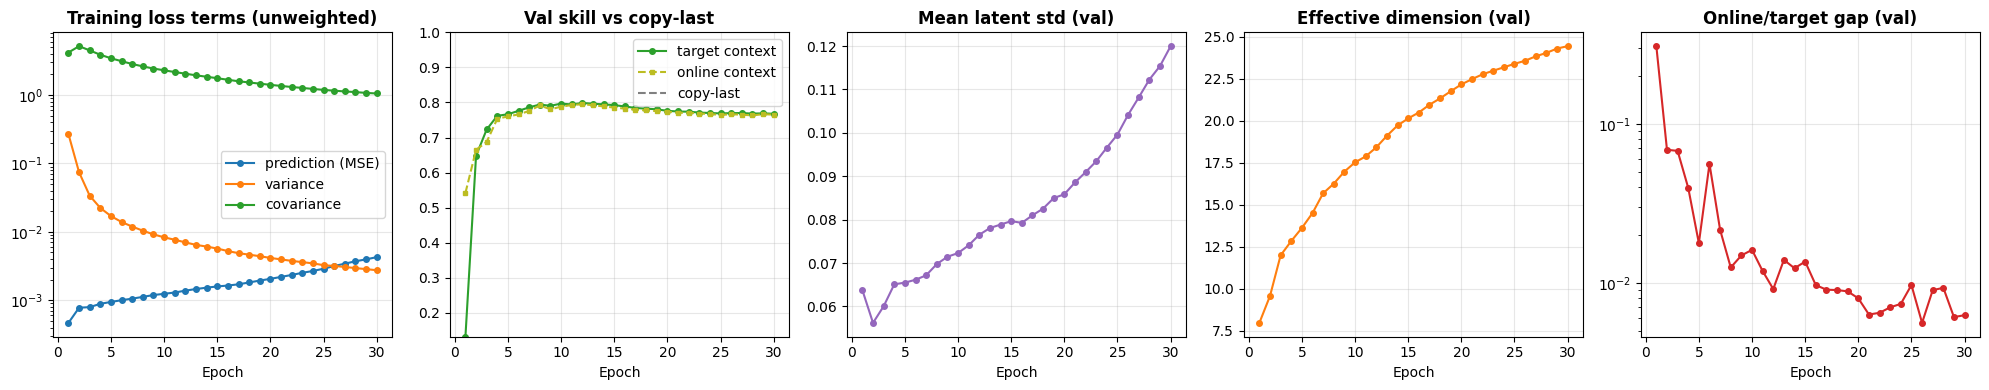

Final val skill (target context): 0.7678
Final val skill (online context): 0.7655
Final effective dimension:        24.45
Final online/target gap:          0.0062


In [5]:
fig = plot_full_jepa_training_curves(history)
plt.show()

print(f"Final val skill (target context): {history['val_skill'][-1]:.4f}")
print(f"Final val skill (online context): {history['val_skill_online'][-1]:.4f}")
print(f"Final effective dimension:        {history['val_effective_dim'][-1]:.2f}")
print(f"Final online/target gap:          {history['val_encoder_gap'][-1]:.4f}")

## **Load Pre-trained Model**
---

If the model has already been trained, the checkpoint can be loaded directly (the training history is stored in it).

In [6]:
checkpoint_path = get_checkpoint_dir() / 'full_jepa.pth'

if checkpoint_path.exists():
    model, checkpoint = load_full_jepa(checkpoint_path, DEVICE)
    history = checkpoint['history']
    print(f"✓ Loaded model from: {checkpoint_path} (epoch {checkpoint['epoch'] + 1})")
else:
    print(f"✗ Checkpoint not found at: {checkpoint_path}")

✓ Loaded model from: /teamspace/studios/this_studio/jepa_cart_pole/checkpoints/full_jepa.pth (epoch 30)


## **Collapse Diagnostics**
---

The latent space of the target encoder on validation episodes: per-dimension standard deviation and PCA spectrum. A collapsed encoder would show all stds near 0 (complete collapse) or a single dominant component (dimensional collapse). Unlike the VAE, there is no prior pulling unused dimensions to $\mathcal{N}(0, 1)$, so the scale of $z$ is arbitrary: only the *shape* of the spectrum matters.

Effective dimension: 24.16
Components for 90% / 99% of the variance: 23 / 29
Online/target gap: 0.0063 of the total latent variance


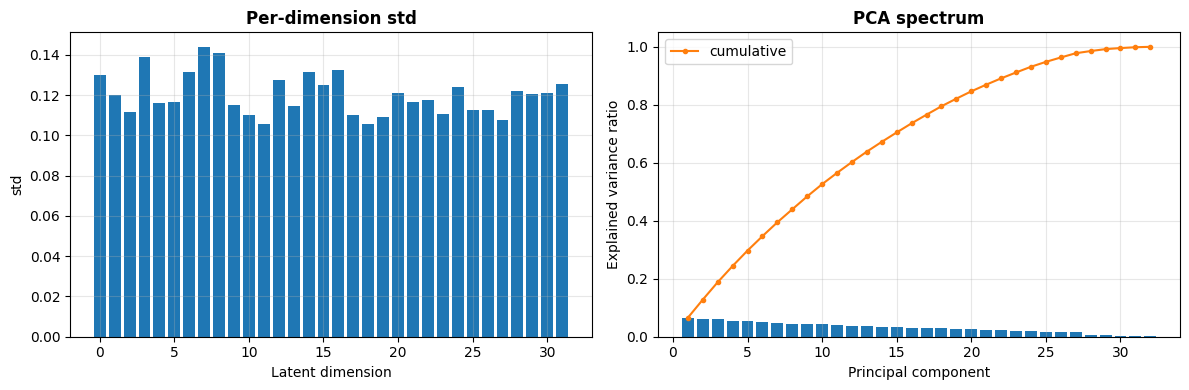

In [7]:
val_images = load_episodes(FRAMES_PATH, checkpoint['val_episodes'][:10], keys=('images',))['images']
z_val = encode_episodes(model.target_encoder, val_images, DEVICE)
z_val_online = encode_episodes(model.encoder, val_images, DEVICE)

flat = z_val.reshape(-1, z_val.shape[-1])
print(f"Effective dimension: {effective_dim(z_val):.2f}")
eig = np.sort(np.linalg.eigvalsh(np.cov(flat, rowvar=False)))[::-1]
cum = np.cumsum(eig) / eig.sum()
print(f"Components for 90% / 99% of the variance: {np.searchsorted(cum, 0.90) + 1} / {np.searchsorted(cum, 0.99) + 1}")
gap = ((z_val_online - z_val) ** 2).reshape(-1, z_val.shape[-1]).sum(axis=1).mean() / flat.var(axis=0).sum()
print(f"Online/target gap: {gap:.4f} of the total latent variance")

fig = plot_latent_spectrum(z_val)
plt.show()

## **Summary and Next Steps**
---

✓ Trained a context encoder and a latent predictor jointly, with an EMA target encoder and VICReg variance/covariance regularisation on an expander

✓ Monitored collapse (std, effective dimension), predictability (skill vs. copy-last) and the online/target gap

**Next steps:**

- **`2-latent_decoder.ipynb`** (optional): train a decoder on the frozen latents to *see* what the JEPA encodes
- **`3-full_jepa_evaluation.ipynb`**: the same evaluation protocol as the VAE world model, for a direct comparison

---

**Model checkpoint saved at**: `checkpoints/full_jepa.pth`